[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch51_LabCh51_Guidance_And_Fast_Sampling.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 51: Guidance, Samplers and Latent Diffusion** (Part XI: Imagining in Depth).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=51](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=51)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch51 - Guidance and fast sampling
## Make the diffusion model of Chapter 50 obey a label, then give it fifty times fewer steps

This lab goes with **Chapter 51** of *The Why Book of Deep Learning, Part 2*. It extends the lab of
Chapter 50 and reuses its functions unchanged.

Chapter 50's model made "a point on one of the moons" in 1,000 network calls. This lab adds the two
things that turn such a model into something you can use: a **request** it obeys, and a **sampler** that
needs far fewer steps and gives the same output for the same starting noise.

| Piece | Part A: points | Part B: digits |
|---|---|---|
| data | two moons, each point labelled with its moon (0 or 1) | MNIST at 16 × 16, labelled with its digit |
| condition | a label embedding added to the time embedding | the same, inside Chapter 50's U-Net |
| training | Chapter 50's loop, with the label hidden 15% of the time | the same |
| guidance | scales 0, 1, 3 and 7; obedience and variety both measured | the same, judged by a small classifier |
| sampler | ancestral (Chapter 50), then a deterministic one at 1,000, 100, 20 and 5 steps | deterministic, 50 steps |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Give a denoiser a label, and count what it costs | Steps 3 and 16 |
| Train one network to answer with and without the label | Step 4 |
| Write classifier-free guidance in three lines and state its convention | Step 6 |
| Measure what the guidance scale buys and what it costs | Steps 6, 7 and 18 |
| Recognise a model that was never trained to be guided | Step 8 |
| Write a deterministic sampler that takes any number of steps | Step 9 |
| Find the step count at which quality breaks | Steps 10 and 19 |
| Use the starting noise as a seed, and move between two seeds | Steps 11, 12 and 20 |
| Edit an existing sample by starting part-way up the noise ladder | Step 14 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** four to five minutes on a laptop CPU. Step 4 (half a minute) and Step 17 (a minute and a
> quarter) are the longest training runs; Steps 7 and 8 retrain the small network too. No GPU is needed. The only download is MNIST from `keras.datasets`.

> **Honest scale:** this is a miniature. The condition is a label with two values (or ten), where a
> text-to-image system has a sentence; the networks have 54,370 and 129,969 parameters, where the
> denoiser of Stable Diffusion (2022) has several hundred million; and nothing here runs in a latent
> space. The **mechanisms** are the real ones. The **numbers** are small-model numbers, good for comparing
> one run in this notebook with another and for nothing else.

> **The convention used all through:** guided noise = unconditional + **scale** × (conditional − unconditional).
> So scale **0** ignores the label, scale **1** is the plain conditional model with **no guidance**, and
> anything above 1 is guidance.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 51
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
# Part A - Points you can plot

## Step 2 - The pieces from Chapter 50, unchanged

These functions are copied from the Chapter 50 lab without a single edit: the two moons, the noise
schedule (every array has length T + 1, and **index t means "after t noising steps"**), the one-jump
forward process `q_sample`, the sinusoidal `TimeEmbedding`, the MLP `build_denoiser`, and the ancestral
sampler `sample`. If any of them is unfamiliar, the Chapter 50 lab builds each one step by step.

Chapter 50 ignored the second thing `make_points` returns: **which moon each point belongs to**. That
label is this lab's "prompt".

> **Predict:** Chapter 50's sampler produced points on both moons. If you wanted 1,000 points on moon 0
> only, and had no label input, what could you do? How many network calls would it waste?

X: (8000, 2) | labels: [4000 4000] | schedule arrays: 1001 (T + 1)
signal weight at t = 0, 250, 500, 750, 1000: [1.     0.7239 0.2803 0.0579 0.0064]


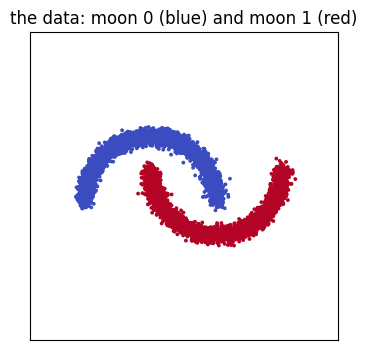

In [2]:
def make_points(n=8000, seed=0):
    """Two interleaved moons. Returns (points of shape (n, 2) float32, moon label of shape (n,))."""
    rng = np.random.default_rng(seed)
    half = n // 2
    a = rng.uniform(0, np.pi, half)
    b = rng.uniform(0, np.pi, n - half)
    upper = np.stack([np.cos(a), np.sin(a)], axis=1)                 # moon 0: an arch
    lower = np.stack([1 - np.cos(b), 0.5 - np.sin(b)], axis=1)       # moon 1: a bowl, shifted right
    x = np.concatenate([upper, lower]) + rng.normal(0, 0.06, (n, 2)) # a little thickness
    y = np.concatenate([np.zeros(half, dtype="int32"), np.ones(n - half, dtype="int32")])
    x = (x - np.array([0.5, 0.25])) / 0.9                            # centre, and scale to roughly unit size
    order = rng.permutation(n)
    return x[order].astype("float32"), y[order]

def nearest_dist(a, b):
    """For every point in a, the distance to its nearest point in b."""
    d2 = ((a[:, None, :] - b[None, :, :]) ** 2).sum(-1)
    return np.sqrt(d2.min(axis=1))

def lims(ax, r=2.6):
    ax.set_xlim(-r, r); ax.set_ylim(-r, r); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

def make_schedule(T=1000, kind="linear"):
    """A noise schedule. Every array has length T + 1; index t = after t noising steps; index 0 = clean data.
    kind = "linear": beta from 0.0001 to 0.02 when T = 1000 (DDPM, 2020), scaled by 1000 / T for other T.
    kind = "cosine": the cosine schedule (2021), which sets the signal left directly and derives beta from it."""
    if kind == "linear":
        beta = np.linspace(1e-4, 0.02, T) * (1000.0 / T)
    elif kind == "cosine":
        s = 0.008
        u = np.arange(T + 1) / T
        f = np.cos((u + s) / (1 + s) * np.pi / 2) ** 2
        beta = np.clip(1 - f[1:] / f[:-1], 0.0, 0.999)
    else:
        raise ValueError(kind)
    beta = np.concatenate([[0.0], beta])                 # beta[0] = 0: step 0 adds nothing
    alpha = 1.0 - beta                                   # fraction of variance kept by one step
    abar = np.cumprod(alpha)                             # fraction of variance kept after t steps ("alpha-bar")
    abar_prev = np.concatenate([[1.0], abar[:-1]])
    one_minus = np.maximum(1.0 - abar, 1e-20)
    return {
        "T": T, "kind": kind, "beta": beta, "alpha": alpha, "abar": abar,
        "signal": np.sqrt(abar),                         # weight on the clean data at step t
        "noise": np.sqrt(1.0 - abar),                    # weight on the noise at step t
        # the three numbers the sampler needs at step t (Step 12 explains them):
        "to_clean": np.sqrt(abar_prev) * beta / one_minus,           # weight on the guess of the clean data
        "to_current": np.sqrt(alpha) * (1.0 - abar_prev) / one_minus,  # weight on the current noisy point
        "sigma": np.sqrt(beta * (1.0 - abar_prev) / one_minus),      # size of the fresh noise added back
    }

def q_sample(x0, t, eps, sched):
    """The forward process in one jump. x0: clean data (n, ...); t: integer steps (n,); eps: noise shaped like x0."""
    shape = (-1,) + (1,) * (x0.ndim - 1)
    sg = sched["signal"][t].reshape(shape).astype("float32")
    nz = sched["noise"][t].reshape(shape).astype("float32")
    return sg * x0 + nz * eps

class TimeEmbedding(layers.Layer):
    """Integer step t, shape (batch,)  ->  sinusoidal vector, shape (batch, dim). No weights."""
    def __init__(self, dim=32, max_period=10000.0, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.max_period = max_period

    def call(self, t):
        ops = keras.ops
        t = ops.cast(ops.reshape(t, (-1, 1)), "float32")
        half = self.dim // 2
        freqs = ops.exp(-np.log(self.max_period) * ops.arange(half, dtype="float32") / half)
        angles = t * ops.reshape(freqs, (1, -1))
        return ops.concatenate([ops.sin(angles), ops.cos(angles)], axis=-1)

    def get_config(self):
        return {**super().get_config(), "dim": self.dim, "max_period": self.max_period}

def build_denoiser(dim=2, width=128, depth=4, emb_dim=32, use_time=True, name="denoiser"):
    """An MLP that predicts the noise in x_t. Inputs: x_t of shape (dim,), and the integer step t.
    use_time=False multiplies the time embedding by zero (for the experiment in Step 15)."""
    x_in = layers.Input(shape=(dim,), name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    e = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    if not use_time:
        e = layers.Rescaling(0.0, name="time_switched_off")(e)
    h = layers.Concatenate(name="join")([x_in, e])
    for i in range(depth):
        h = layers.Dense(width, activation="swish", name=f"dense{i + 1}")(h)
    out = layers.Dense(dim, name="noise")(h)                       # no activation: noise has no range
    return keras.Model([x_in, t_in], out, name=name)

def sample(model, sched, n, shape=(2,), seed=0, fresh_noise=True, clip=None, keep=()):
    """Ancestral sampling. Start from pure noise and walk from t = T down to t = 1.
    Returns (samples, snapshots) where snapshots[t] is the batch after reaching step t, for every t in keep."""
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((n,) + tuple(shape)).astype("float32")           # pure noise: step T
    snaps = {sched["T"]: x.copy()} if sched["T"] in keep else {}
    for t in range(sched["T"], 0, -1):
        eps_hat = model.predict_on_batch([x, np.full(n, t, dtype="int32")])  # 1. predict the noise ...
        x0_hat = (x - sched["noise"][t] * eps_hat) / sched["signal"][t]      #    ... and guess the clean data
        if clip is not None:
            x0_hat = np.clip(x0_hat, -clip, clip)
        x = sched["to_clean"][t] * x0_hat + sched["to_current"][t] * x       # 2. step a little towards the guess
        if fresh_noise:
            x = x + sched["sigma"][t] * rng.standard_normal(x.shape)         # 3. add fresh noise
        x = x.astype("float32")
        if t - 1 in keep:
            snaps[t - 1] = x.copy()
    return x, snaps

X, Y = make_points(8000, seed=0)             # the training set, with its labels this time
X_REAL, Y_REAL = make_points(2000, seed=1)   # fresh points from the same moons, never trained on
SCHED = make_schedule(1000, "linear")
T = SCHED["T"]
MOON = [X[Y == 0], X[Y == 1]]                # the training points of each moon
print("X:", X.shape, "| labels:", np.bincount(Y), "| schedule arrays:", len(SCHED["beta"]), "(T + 1)")
print("signal weight at t = 0, 250, 500, 750, 1000:", SCHED["signal"][[0, 250, 500, 750, 1000]])

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X[:, 0], X[:, 1], s=3, c=Y, cmap="coolwarm"); lims(ax); ax.set_title("the data: moon 0 (blue) and moon 1 (red)"); plt.show()

### Why we see this

Without a label input the only way to get 1,000 points on moon 0 is to generate about 2,000 and throw
half away. With two classes that is a nuisance. With "a watercolour of a lighthouse at dusk" it is
hopeless: you would wait for ever for the right picture to turn up by chance. A generator becomes useful
when the request goes **in**.

---
## Step 3 - A denoiser that takes a request, counted

The network gets a third input: the label. It is looked up in a small table (an `Embedding` layer,
Chapter 18) that gives a vector of 32 numbers, the same size as the time embedding, and the two are
**added**. Everything after that is Chapter 50's MLP.

The table has **three** rows, not two: moon 0, moon 1, and a third row that means **"no label given"**.
Step 4 explains what the third row is for.

> **Predict:** Chapter 50's denoiser has 54,274 parameters. How many does the label table add? Does
> adding (not joining) the label to the time embedding change the size of the first Dense layer?

In [3]:
NULL = 2                                     # the label that means "no label given"

def build_cond_denoiser(dim=2, width=128, depth=4, emb_dim=32, n_labels=2, name="cond_denoiser"):
    """Chapter 50's MLP with a label. Inputs: x_t (dim,), the step t, and a label 0 ... n_labels,
    where the last value (n_labels) means "no label". The label's vector is added to the time embedding."""
    x_in = layers.Input(shape=(dim,), name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    c_in = layers.Input(shape=(), dtype="int32", name="label")
    e = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    c = layers.Embedding(n_labels + 1, emb_dim, name="label_embedding")(c_in)   # one row per label + "none"
    e = layers.Add(name="time_plus_label")([e, c])
    h = layers.Concatenate(name="join")([x_in, e])
    for i in range(depth):
        h = layers.Dense(width, activation="swish", name=f"dense{i + 1}")(h)
    out = layers.Dense(dim, name="noise")(h)
    return keras.Model([x_in, t_in, c_in], out, name=name)

plain = build_denoiser()
MLP_50 = plain.count_params()
label_table = 3 * 32
print(f"Chapter 50's denoiser        : {MLP_50:,}")
print(f"label table, 3 rows x 32     : {label_table:,}")
print(f"hand count                   : {MLP_50 + label_table:,}")

keras.utils.set_random_seed(SEED)
cond = build_cond_denoiser()
assert MLP_50 == 54_274 and cond.count_params() == MLP_50 + label_table == 54_370
print(f"Keras count                  : {cond.count_params():,}")
print("inputs:", [tuple(i.shape) for i in cond.inputs], "-> output:", cond.output_shape)

Chapter 50's denoiser        : 54,274
label table, 3 rows x 32     : 96
hand count                   : 54,370
Keras count                  : 54,370
inputs: [(None, 2), (None,), (None,)] -> output: (None, 2)


### Why we see this

96 parameters, less than 0.2% of the network. Because the label vector is **added** to the time vector,
the first Dense layer still sees 2 + 32 inputs and nothing else changes size. A condition is cheap to
wire in. What it costs is data: every training example now needs a label.

This is how a class label enters a full-size model too. A sentence cannot be squeezed through the same
door, because it is a sequence of vectors and not one vector; the chapter explains how cross-attention
handles that. The principle is the same: **extra input that tells the denoiser what the clean data
should be.**

---
## Step 4 - Train it, hiding the label now and then

`train_cond_denoiser` is Chapter 50's `train_denoiser` with three marked lines added. The network is fed
the label and trained on exactly the same target as before: the noise.

One of the new lines replaces the label by `NULL` for a random **15%** of the examples in every round.
Those examples teach the third row of the table to mean "this could be either moon", so that **one
network can answer both ways**: with the label, and without it.

> **Predict:** Chapter 50's unconditional denoiser reached a loss of about 0.19. This one is told which
> moon the point came from. Will its loss be higher, the same, or lower? Why should a label make
> **noise** easier to guess?

In [4]:
def train_cond_denoiser(model, x0, labels, sched, rounds, reps=1, batch=256, lr=2e-3, drop=0.15, null=NULL,
                        seed=0, verbose=True):
    """Chapter 50's noise-prediction training with a label. drop = share of examples whose label is hidden."""
    rng = np.random.default_rng(seed)
    data = np.tile(x0, (reps,) + (1,) * (x0.ndim - 1))
    lab = np.tile(labels, reps).astype("int32")                                 # NEW: the labels, repeated too
    steps = rounds * int(np.ceil(len(data) / batch))
    model.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(lr, steps)), loss="mse")
    history = []
    for r in range(rounds):
        t = rng.integers(1, sched["T"] + 1, size=len(data))            # a random step for every example
        eps = rng.standard_normal(data.shape).astype("float32")        # the noise
        x_t = q_sample(data, t, eps, sched)                            # mix
        c = np.where(rng.random(len(data)) < drop, null, lab).astype("int32")   # NEW: hide some labels
        h = model.fit([x_t, t, c], eps, batch_size=batch, epochs=1, verbose=0)  # NEW: the label goes in
        history.append(h.history["loss"][0])
        if verbose and (r % max(1, rounds // 8) == 0 or r == rounds - 1):
            print(f"round {r + 1:3d} / {rounds}   loss {history[-1]:.4f}")
    return history

t0 = time.time()
hist = train_cond_denoiser(cond, X, Y, SCHED, rounds=40, reps=10, batch=512, seed=SEED)
print(f"trained in {time.time() - t0:.0f} s: {40 * int(np.ceil(80000 / 512)):,} steps of batch 512")

round   1 / 40   loss 0.2445


round   6 / 40   loss 0.1682


round  11 / 40   loss 0.1588


round  16 / 40   loss 0.1564


round  21 / 40   loss 0.1549


round  26 / 40   loss 0.1534


round  31 / 40   loss 0.1513


round  36 / 40   loss 0.1516


round  40 / 40   loss 0.1512
trained in 26 s: 6,280 steps of batch 512


### Why we see this

The loss settles near **0.15**, below Chapter 50's 0.19. The label removes one source of doubt. A noisy
point half-way between the moons could have come from either; told "moon 0", the network knows which
clean points to consider, so its guess of the clean point is sharper, and a sharper guess of the clean
point **is** a sharper guess of the noise (the two are tied by the one-jump formula).

The loss is still read against 1.0 and still says little about the samples. Carry on.

---
## Step 5 - One network, two answers

Ask the trained network about the same noisy points three ways: with the **right** label, with **no**
label, and with the **wrong** label. Where in the schedule does the label matter?

> **Predict:** at step 1,000 the input is almost pure noise. Can a label change the best guess of the
> noise there? And at step 10, where the point is nearly clean and plainly on one moon?

In [5]:
rng = np.random.default_rng(SEED)
none = np.full(len(X_REAL), NULL, dtype="int32")
print(f"{'step':>5} {'signal':>7} | {'error with right label':>23} {'no label':>9} {'wrong label':>12} | {'size of (right - none)':>23}")
GAP = {}
for t in (1000, 750, 500, 250, 100, 50, 10):
    eps = rng.standard_normal(X_REAL.shape).astype("float32")
    tt = np.full(len(X_REAL), t, dtype="int32")
    x_t = q_sample(X_REAL, tt, eps, SCHED)
    right = cond.predict_on_batch([x_t, tt, Y_REAL])
    unlab = cond.predict_on_batch([x_t, tt, none])
    wrong = cond.predict_on_batch([x_t, tt, 1 - Y_REAL])
    GAP[t] = float(np.linalg.norm(right - unlab, axis=1).mean())
    print(f"{t:5d} {SCHED['signal'][t]:7.3f} | {np.mean((right - eps) ** 2):23.3f} {np.mean((unlab - eps) ** 2):9.3f}"
          f" {np.mean((wrong - eps) ** 2):12.3f} | {GAP[t]:23.3f}")

 step  signal |  error with right label  no label  wrong label |  size of (right - none)
 1000   0.006 |                   0.001     0.001        0.001 |                   0.032
  750   0.058 |                   0.002     0.002        0.005 |                   0.049
  500   0.280 |                   0.031     0.050        0.110 |                   0.194
  250   0.724 |                   0.245     0.346        0.814 |                   0.394
  100   0.947 |                   0.441     0.623        2.934 |                   0.358
   50   0.985 |                   0.518     0.649        5.580 |                   0.325
   10   0.999 |                   0.842     0.878        6.236 |                   0.222


### Why we see this

At steps 1,000 and 750 the three answers are the same to two decimal places: the input is nearly all
noise, "the noise is the input" is nearly right, and no label can improve on it. The label starts to
matter round step 500 and matters most between about 250 and 50, which is where Chapter 50 found the
sampler deciding **which moon and roughly where**. The wrong label is much worse than no label: the
network is being told to explain a point on one moon as a point from the other, and it invents a large
"noise" to do so.

The last column is the important one for what follows. `right − none` is a small **arrow**: the change
in the noise guess that the label causes. It is the direction "more like what was asked for". Guidance
is nothing more than making that arrow longer.

---
## Step 6 - Classifier-free guidance

At every step of sampling, ask the network twice (with the label and without) and combine:

**guided noise = unconditional + scale × (conditional − unconditional)**

| scale | what you get |
|---|---|
| 0 | the unconditional guess: the label is ignored |
| 1 | the conditional guess exactly: **no guidance** |
| above 1 | past the conditional guess, further along the arrow: **guidance** |

`Guided` wraps a model, a batch of labels and a scale, and offers the one method the sampler calls,
`predict_on_batch([x, t])`. So Chapter 50's `sample` runs it **without any change**: the sampler does
not know that guidance exists. Guidance changes what noise is predicted; the sampler decides what to
do with the prediction. They are separate parts.

Three things are measured for every scale, on 1,000 points requested from each moon:

* **obeys** (fidelity to the request): the share of points that land nearer the requested moon than the other one;
* **off** (quality): the share that are more than 0.1 from **any** moon, as in Chapter 50;
* **spread** and **miss** (variety): the standard deviation along x of the points that reached the
  requested moon, averaged over the two moons; and how far a real point of the requested moon is from
  the nearest sample (smaller is better).

> **Predict:** at scale 0, what share of points obey? At scale 1? Then the interesting one: from scale 1
> to 3 to 7, what happens to the spread, and does anything else go wrong?

fresh real points (yardstick)  obeys 100.0% | off   0.0% | spread 0.79 | miss 0.017



scale 0                        obeys  51.8% | off   6.7% | spread 0.76 | miss 0.027
                               network inputs processed: 2,000,000 | 2.8 s


scale 1                        obeys 100.0% | off   0.0% | spread 0.79 | miss 0.017
                               network inputs processed: 2,000,000 | 2.8 s


scale 3                        obeys 100.0% | off   0.1% | spread 0.65 | miss 0.027
                               network inputs processed: 4,000,000 | 3.5 s


scale 7                        obeys 100.0% | off  19.2% | spread 0.63 | miss 0.039
                               network inputs processed: 4,000,000 | 3.2 s


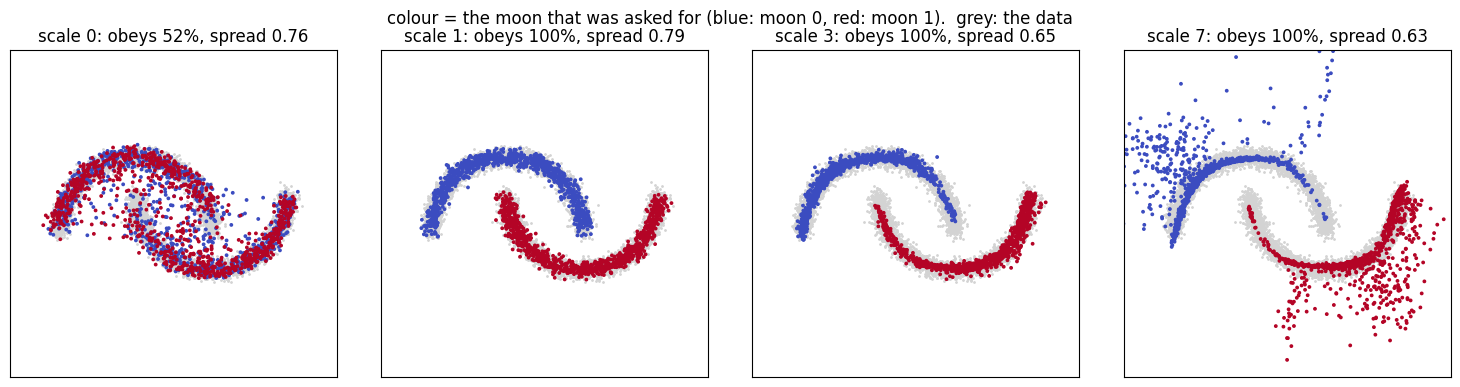

In [6]:
class Guided:
    """Classifier-free guidance, dressed as a model: it has the one method that the samplers call.
    guided noise = base + scale * (conditional - base), where base is the "no label" answer."""
    def __init__(self, model, labels, scale, null=NULL):
        self.model = model
        self.labels = np.asarray(labels, dtype="int32")
        self.scale = float(scale)
        self.base = np.full(len(self.labels), null, dtype="int32")
        self.rows = 0                                   # how many inputs the network has processed

    def predict_on_batch(self, inputs):
        x, t = inputs
        n = len(x)
        if self.scale == 1.0:                           # no guidance: one call, with the label
            self.rows += n
            return self.model.predict_on_batch([x, t, self.labels])
        if self.scale == 0.0:                           # label ignored: one call, without it
            self.rows += n
            return self.model.predict_on_batch([x, t, self.base])
        self.rows += 2 * n                              # guidance: every point goes through twice
        both = self.model.predict_on_batch([np.concatenate([x, x]), np.concatenate([t, t]),
                                            np.concatenate([self.labels, self.base])])
        cond_eps, base_eps = both[:n], both[n:]
        return base_eps + self.scale * (cond_eps - base_eps)

def judge_points(g, want, name, quiet=False):
    """Fidelity and variety of generated points g, where want[i] is the moon that point i was asked to be on."""
    obeys, off, spread, miss = [], [], [], []
    for c in (0, 1):
        s = g[want == c]
        d_own, d_other = nearest_dist(s, MOON[c]), nearest_dist(s, MOON[1 - c])
        obeys.append((d_own < d_other).mean()); off.append((np.minimum(d_own, d_other) > 0.1).mean())
        spread.append(s[d_own < d_other][:, 0].std()); miss.append(nearest_dist(X_REAL[Y_REAL == c], s).mean())
    out = (100 * np.mean(obeys), 100 * np.mean(off), float(np.mean(spread)), float(np.mean(miss)))
    if not quiet:
        print(f"{name:30s} obeys {out[0]:5.1f}% | off {out[1]:5.1f}% | spread {out[2]:.2f} | miss {out[3]:.3f}")
    return out

WANT = np.repeat([0, 1], 1000).astype("int32")          # ask for 1,000 points on each moon
judge_points(*make_points(2000, seed=2), "fresh real points (yardstick)")
print()
SCALES = (0, 1, 3, 7)
by_scale, score_scale = {}, {}
for w in SCALES:
    g_model = Guided(cond, WANT, w)
    t0 = time.time()
    by_scale[w], _ = sample(g_model, SCHED, len(WANT), seed=SEED)
    dt = time.time() - t0
    score_scale[w] = judge_points(by_scale[w], WANT, f"scale {w}")
    print(f"{'':30s} network inputs processed: {g_model.rows:,} | {dt:.1f} s")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.9))
for a, w in zip(ax, SCALES):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
    a.scatter(by_scale[w][:, 0], by_scale[w][:, 1], s=3, c=WANT, cmap="coolwarm"); lims(a, 2.4)
    a.set_title(f"scale {w}: obeys {score_scale[w][0]:.0f}%, spread {score_scale[w][2]:.2f}")
plt.suptitle("colour = the moon that was asked for (blue: moon 0, red: moon 1).  grey: the data"); plt.tight_layout(); plt.show()

### Why we see this

**Scale 0** ignores the request: about half the points land on the requested moon, by luck.

**Scale 1** is the conditional model with no guidance. On this easy problem it already obeys every
time, and its points are as spread out and cover the moon as well as real points do. Remember this line:
**when the plain conditional model is good, guidance has nothing to add.**

**Scale 3** still obeys, of course. Look at what it cost: the spread has fallen from 0.79 to 0.65 and
the miss score has risen. The points have drawn away from the other moon, and the parts of each moon
that lie close to the other one (the tips that tuck into the neighbour's hollow) are thinly covered.
The request was "moon 0"; guidance delivers "the most moon-0-ish part of moon 0".

**Scale 7** is the 2-D picture of a "burnt" image. About a fifth of the points are no longer on any
moon: they have been pushed past the data, outwards, away from the other class. The arrow was multiplied
by seven at every one of a thousand steps, and the result is a place the data never visits.

The cost in compute is in the last line of each pair: with guidance every point goes through the
network **twice** per step. Real systems batch the two together exactly as `Guided` does, so the time
does not quite double, but the work does.

---
## Step 7 - When guidance pays: a model taught with careless labels

In Step 6 guidance bought nothing, because the labels were perfect and the two moons are easy to tell
apart. A text-to-image model is not so lucky. Its "labels" are captions collected from the web, and a
caption describes its picture loosely: it leaves things out, mentions things that are not there, or is
about something else. To imitate that, **give a quarter of the training points the wrong label** and
train the same network again.

> **Predict:** this model has learnt, faithfully, that "moon 0" means moon 0 three times out of four.
> What share of its points will obey at scale 1? What will scales 3 and 7 do to that share? And will
> the points still be **on** the moons?

training labels that are wrong: 25.5%


careless labels, scale 0       obeys  51.4% | off   0.8% | spread 0.79 | miss 0.024


careless labels, scale 1       obeys  76.5% | off   1.2% | spread 0.79 | miss 0.019


careless labels, scale 2       obeys  91.5% | off   0.2% | spread 0.76 | miss 0.018


careless labels, scale 3       obeys  97.0% | off   0.2% | spread 0.71 | miss 0.019


careless labels, scale 7       obeys 100.0% | off   0.1% | spread 0.55 | miss 0.032


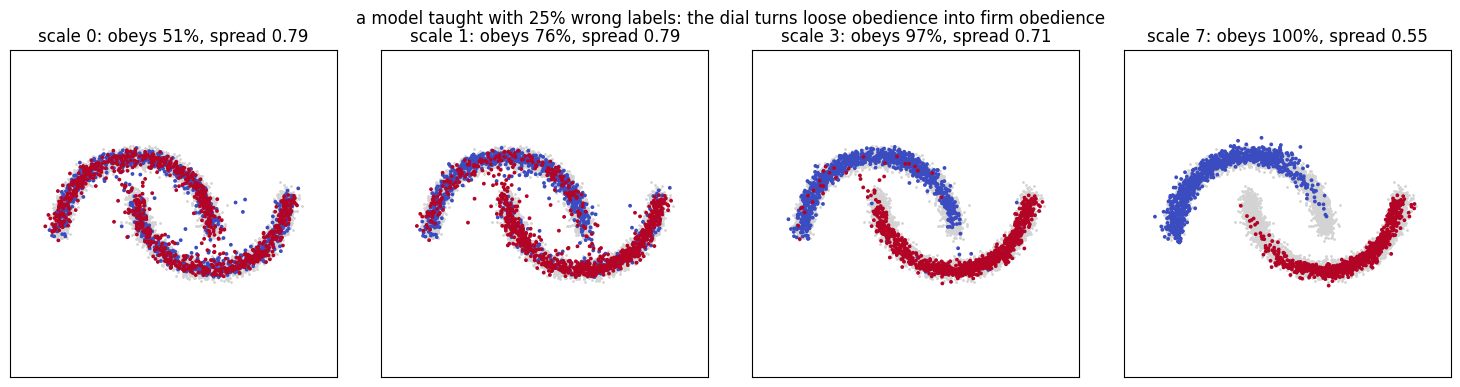

In [7]:
rng = np.random.default_rng(SEED)
Y_CARELESS = np.where(rng.random(len(Y)) < 0.25, 1 - Y, Y).astype("int32")       # a quarter of the labels flipped
print(f"training labels that are wrong: {100 * (Y_CARELESS != Y).mean():.1f}%")
keras.utils.set_random_seed(SEED)
loose = build_cond_denoiser(name="taught_with_careless_labels")
train_cond_denoiser(loose, X, Y_CARELESS, SCHED, rounds=40, reps=10, batch=512, seed=SEED, verbose=False)
LOOSE_SCALES = (0, 1, 2, 3, 7)
loose_by_scale, loose_score = {}, {}
for w in LOOSE_SCALES:
    loose_by_scale[w], _ = sample(Guided(loose, WANT, w), SCHED, len(WANT), seed=SEED)
    loose_score[w] = judge_points(loose_by_scale[w], WANT, f"careless labels, scale {w}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.9))
for a, w in zip(ax, (0, 1, 3, 7)):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
    a.scatter(loose_by_scale[w][:, 0], loose_by_scale[w][:, 1], s=3, c=WANT, cmap="coolwarm"); lims(a, 2.4)
    a.set_title(f"scale {w}: obeys {loose_score[w][0]:.0f}%, spread {loose_score[w][2]:.2f}")
plt.suptitle("a model taught with 25% wrong labels: the dial turns loose obedience into firm obedience"); plt.tight_layout(); plt.show()

### Why we see this

Now the dial does what it is famous for. At **scale 1** about three quarters of the points land on the
requested moon. That is not a fault of the network: it learnt exactly what its careless labels taught
it. At **scale 2** about nine in ten obey, at **scale 3** about 97 in a hundred, and at **scale 7**
all of them. The points stay on the moons throughout.

Why does it work? For this model the label is a **lean**, not a command: "moon 0" makes moon 0 more
likely than it is without a label. The arrow (conditional − unconditional) points towards "more likely
under this label than on average". Lengthen the arrow and the lean is exaggerated into a rule. Nothing
was retrained. This is why classifier-free guidance is switched on in every text-to-image system: **a
model that follows the request loosely can be made to follow it firmly, at sampling time.**

Read the spread column before celebrating. The points that obey cover less and less of their moon as
the scale rises. The price of obedience is variety, here exactly as in Step 6. The dial has a best
setting, and it is not "as high as it goes".

---
## Step 8 - The trap: a model that never saw a hidden label

Train the network once more on the correct labels with `drop=0.0`: the label is always given. The third
row of the label table ("no label") is then never used in training and keeps its random starting values.
Everything else is the same as in Step 4, so the Step 6 results are the fair comparison.

> **Predict:** this model has seen more labelled examples than the Step 4 model. At scale 1 will it be
> worse, the same, or better? What will scale 3 do, given what the "unconditional" answer now is?

In [8]:
keras.utils.set_random_seed(SEED)
never = build_cond_denoiser(name="never_dropped")
train_cond_denoiser(never, X, Y, SCHED, rounds=40, reps=10, batch=512, seed=SEED, drop=0.0, verbose=False)
never_score = {}
for w in (1, 0, 3):
    never_score[w] = judge_points(sample(Guided(never, WANT, w), SCHED, len(WANT), seed=SEED)[0], WANT, f"never dropped, scale {w}")
print()
for w in (1, 0, 3):
    print(f"{'dropped 15% (Step 6), scale ' + str(w):30s} obeys {score_scale[w][0]:5.1f}% | off {score_scale[w][1]:5.1f}%"
          f" | spread {score_scale[w][2]:.2f} | miss {score_scale[w][3]:.3f}")

never dropped, scale 1         obeys 100.0% | off   0.0% | spread 0.79 | miss 0.017


never dropped, scale 0         obeys  51.1% | off  80.8% | spread 0.77 | miss 0.242


never dropped, scale 3         obeys 100.0% | off  99.4% | spread 0.69 | miss 0.415

dropped 15% (Step 6), scale 1  obeys 100.0% | off   0.0% | spread 0.79 | miss 0.017
dropped 15% (Step 6), scale 0  obeys  51.8% | off   6.7% | spread 0.76 | miss 0.027
dropped 15% (Step 6), scale 3  obeys 100.0% | off   0.1% | spread 0.65 | miss 0.027


### Why we see this

At scale 1 the never-dropped model is as good as the Step 4 model: that is the only question it was
trained to answer. At scale 0 it is asked a question it has never seen, with a label vector made of
random numbers, and a large share of its points land on no moon at all. At scale 3 the guided answer is
"three times as far from nonsense as the truth is", which is more nonsense: almost every point is off
the moons. The model trained **with** dropping behaves at all three scales.

Nothing warns you. The code runs, the scale-1 samples look healthy, and the guided ones are ruined.
**A model can only be guided if it was trained with the condition dropped.** The usual share is 10 to
20%.

---
## Step 9 - A sampler that can take big steps

Chapter 50 (its Step 16) showed that visiting every tenth step with the one-step weights fails. The
repair is to stop thinking in steps of one. Every pass of the sampler already makes a **guess of the
clean point** and a **guess of the noise**. The forward formula says what a point at **any** step looks
like, given those two:

**point at step s = (signal weight at s) × clean guess + (noise weight at s) × noise guess**

So from step t you can jump to any earlier step s directly: no weights for "one step" are needed, only
the schedule's signal and noise weights at s. That is the sampler of the 2020 paper called **DDIM**. It
has two properties that the ancestral sampler lacks:

1. it takes any list of steps you like, for example 20 evenly spaced ones;
2. it adds **no fresh noise**, so the only random numbers are the starting noise.

The dial `eta` puts fresh noise back: `eta=0` is the deterministic sampler, `eta=1` is as random as the
ancestral one (and with all 1,000 steps it **is** the ancestral sampler, written another way).

> **Predict:** Chapter 50 deleted the fresh noise from the ancestral sampler and every point collapsed
> into one clump. This sampler has no fresh noise either. Why should it not collapse? (Look at which
> noise it re-uses.)

In [9]:
def ddim_sample(model, sched, n, steps, shape=(2,), seed=0, eta=0.0, clip=None, x_start=None, start=None, record=None):
    """A DDIM-style sampler: `steps` evenly spaced jumps from t = T down to 0.
    eta = 0: deterministic (no fresh noise).  eta = 1: as random as ancestral sampling.
    x_start: the batch to start from (noise drawn from `seed` if not given).
    start: the step that x_start is at (T if not given).  record: a list to collect (step, batch)."""
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((n,) + tuple(shape)).astype("float32") if x_start is None else np.array(x_start, dtype="float32")
    top = sched["T"] if start is None else start
    ts = np.unique(np.round(np.linspace(0, top, steps + 1)).astype(int))     # the steps visited: 0 ... top
    abar = sched["abar"]
    if record is not None:
        record.append((int(ts[-1]), x.copy()))
    for i in range(len(ts) - 1, 0, -1):
        t, s = ts[i], ts[i - 1]                                              # jump from step t to step s
        eps_hat = model.predict_on_batch([x, np.full(n, t, dtype="int32")])  # 1. predict the noise ...
        x0_hat = (x - sched["noise"][t] * eps_hat) / sched["signal"][t]      #    ... and guess the clean data
        if clip is not None:
            x0_hat = np.clip(x0_hat, -clip, clip)
            eps_hat = (x - sched["signal"][t] * x0_hat) / sched["noise"][t]  #    keep the two guesses consistent
        fresh = eta * np.sqrt((1 - abar[s]) / (1 - abar[t]) * (1 - abar[t] / abar[s]))   # 0 when eta = 0
        x = sched["signal"][s] * x0_hat + np.sqrt(max(1 - abar[s] - fresh ** 2, 0.0)) * eps_hat   # 2. re-noise to step s
        if fresh > 0:
            x = x + fresh * rng.standard_normal(x.shape)                     # 3. optional fresh noise
        x = x.astype("float32")
        if record is not None:
            record.append((int(s), x.copy()))
    return x

# check 1: with eta = 1 and every step, the fresh-noise size is Chapter 50's sigma
fresh_all = np.sqrt((1 - SCHED["abar"][:-1]) / (1 - SCHED["abar"][1:]) * (1 - SCHED["abar"][1:] / SCHED["abar"][:-1]))
assert np.allclose(fresh_all, SCHED["sigma"][1:])
print("eta = 1 with all 1,000 steps: fresh noise at t = 1000, 500, 1 :", fresh_all[[999, 499, 0]].round(4), "= Chapter 50's sigma")

# check 2: the steps visited
for k in (1000, 100, 20, 5):
    ts = np.unique(np.round(np.linspace(0, T, k + 1)).astype(int))
    print(f"{k:5d} steps visit: {ts[::-1][:6].tolist()} ... {ts[::-1][-2:].tolist()}")

# check 3: statistics. Deterministic, 1,000 steps, no guidance (scale 1).
g_det = ddim_sample(Guided(cond, WANT, 1), SCHED, len(WANT), 1000, seed=SEED)
judge_points(by_scale[1], WANT, "ancestral, 1,000 steps")
DET_1000 = judge_points(g_det, WANT, "deterministic, 1,000 steps")

eta = 1 with all 1,000 steps: fresh noise at t = 1000, 500, 1 : [0.1414 0.1002 0.    ] = Chapter 50's sigma
 1000 steps visit: [1000, 999, 998, 997, 996, 995] ... [1, 0]
  100 steps visit: [1000, 990, 980, 970, 960, 950] ... [10, 0]
   20 steps visit: [1000, 950, 900, 850, 800, 750] ... [50, 0]
    5 steps visit: [1000, 800, 600, 400, 200, 0] ... [200, 0]


ancestral, 1,000 steps         obeys 100.0% | off   0.0% | spread 0.79 | miss 0.017


deterministic, 1,000 steps     obeys 100.0% | off   0.3% | spread 0.79 | miss 0.018


### Why we see this

The deterministic sampler does not collapse: the spread and coverage match the ancestral sampler's.
Chapter 50's broken sampler moved each point towards an **average** and added nothing back. This one
re-noises the clean guess to step s using **the noise the network has just found in the point**. That
noise is the point's own, it is carried along from step to step, and it keeps the cloud as wide as the
schedule says it should be at every step. No dice are needed after the first throw.

With `eta=1` and every step the fresh noise is exactly Chapter 50's `sigma` (the assert), so the
ancestral sampler is one member of this family.

---
## Step 10 - 1,000, 100, 20 and 5 steps

Same trained network, same starting noise, fewer and fewer steps. Both the deterministic sampler
(`eta=0`) and the random one (`eta=1`), respaced properly this time.

> **Predict:** write down the smallest number of steps at which you expect the moons to be as good as
> with 1,000. Then predict the **kind** of damage when there are too few: a haze round the moons, or
> something else? (Chapter 50, Step 11: what does a single big jump return?)

                                          deterministic (eta 0)                       random (eta 1)        


 1000 steps   2.73 s           off   0.3% | spread 0.79 | miss 0.018      off   0.0% | spread 0.79 | miss 0.017


  100 steps   0.27 s           off   0.4% | spread 0.78 | miss 0.018      off   0.0% | spread 0.78 | miss 0.019


   50 steps   0.13 s           off   0.2% | spread 0.77 | miss 0.020      off   0.1% | spread 0.76 | miss 0.022


   20 steps   0.06 s           off   0.6% | spread 0.75 | miss 0.032      off   0.2% | spread 0.72 | miss 0.032


   10 steps   0.03 s           off   1.9% | spread 0.70 | miss 0.042      off   2.6% | spread 0.66 | miss 0.043


    5 steps   0.01 s           off  15.4% | spread 0.56 | miss 0.100      off  15.4% | spread 0.54 | miss 0.092


    2 steps   0.01 s           off  33.1% | spread 0.20 | miss 0.438      off  42.5% | spread 0.37 | miss 0.240

20 steps against 1,000: 49 times faster


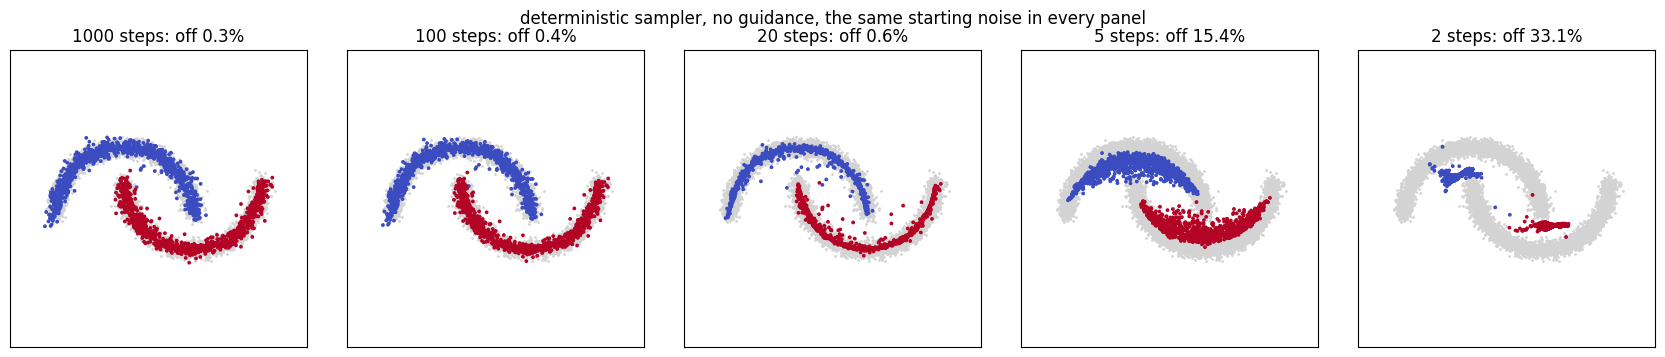

In [10]:
STEP_COUNTS = (1000, 100, 50, 20, 10, 5, 2)
by_steps, score_steps, time_steps = {}, {}, {}
print(f"{'':30s} {'deterministic (eta 0)':^44s}   {'random (eta 1)':^30s}")
for k in STEP_COUNTS:
    t0 = time.time()
    by_steps[k] = ddim_sample(Guided(cond, WANT, 1), SCHED, len(WANT), k, seed=SEED)
    time_steps[k] = time.time() - t0
    score_steps[k] = judge_points(by_steps[k], WANT, "", quiet=True)
    r = judge_points(ddim_sample(Guided(cond, WANT, 1), SCHED, len(WANT), k, seed=SEED, eta=1.0), WANT, "", quiet=True)
    d = score_steps[k]
    print(f"{k:5d} steps {time_steps[k]:6.2f} s           off {d[1]:5.1f}% | spread {d[2]:.2f} | miss {d[3]:.3f}      "
          f"off {r[1]:5.1f}% | spread {r[2]:.2f} | miss {r[3]:.3f}")
print(f"\n20 steps against 1,000: {time_steps[1000] / time_steps[20]:.0f} times faster")

fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, k in zip(ax, (1000, 100, 20, 5, 2)):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
    a.scatter(by_steps[k][:, 0], by_steps[k][:, 1], s=3, c=WANT, cmap="coolwarm"); lims(a, 2.4)
    a.set_title(f"{k} steps: off {score_steps[k][1]:.1f}%")
plt.suptitle("deterministic sampler, no guidance, the same starting noise in every panel"); plt.tight_layout(); plt.show()

### Why we see this

A hundred steps are indistinguishable from a thousand, at a tenth of the cost. Twenty steps are still
good: a little coverage has been lost (the miss score), and little you would see without the numbers.
At ten the damage is measurable. **At five it is plain**: about one point in seven is off the moons, and
at two the picture is wrecked. On this problem the curve of quality against steps is flat from 1,000
down to about 20 and then falls off a cliff. That shape, a long plateau and a cliff, is the general one;
**where** the cliff stands depends on the model, the data and the sampler.

Look at **how** the 5-step picture is wrong. It is not a haze. The moons have **shrunk**: the spread is
0.54 where the data's is 0.79, and the points sit towards the inside of each crescent. At two steps
each moon has collapsed to a short dash. Every big jump trusts the guess of the clean point, and a guess
made from a very noisy point is an **average** of the possibilities (Chapter 50). Too few steps means
too much trust in averages.

The random sampler does no better than the deterministic one at few steps here, and with the full
thousand it is very slightly cleaner. Fresh noise costs steps to absorb; it also washes out small errors
made earlier.

---
## Step 11 - Same noise, same picture

With no fresh noise, the starting noise is the **only** random input. Three consequences, each checked
with a number:

1. run the deterministic sampler twice from the same noise: is the output the same?
2. run the **random** sampler twice from the same starting noise: is it?
3. start the deterministic sampler from the same noise with 1,000, 100, 20 and 5 steps: does each point
   end in the **same place**, or only on the same moon?

> **Predict:** for the third question, guess the typical distance between where a point ends with 100
> steps and where the same starting noise ends with 20. The moons are about 0.13 thick and 3.5 long.

1. deterministic, twice           : largest difference 0.000000


2. random sampler, twice          : mean distance between the two ends 1.001
   two unrelated points of a moon : mean distance 1.041
3. deterministic, same noise, different step counts (distance from the 100-step result):


    1000 steps: median distance 0.011
      20 steps: median distance 0.058
      10 steps: median distance 0.106
       5 steps: median distance 0.274
4. same noise, deterministic against random sampler: mean distance 1.018


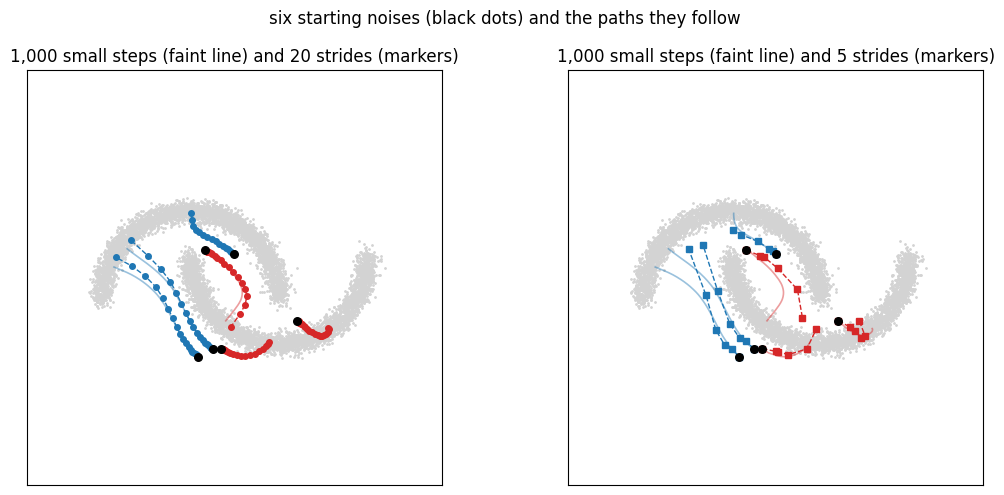

In [11]:
rng = np.random.default_rng(7)
z = rng.standard_normal((len(WANT), 2)).astype("float32")                  # one fixed batch of starting noise
run = lambda k, **kw: ddim_sample(Guided(cond, WANT, 1), SCHED, len(WANT), k, x_start=z, **kw)

a, b = run(100), run(100)
print(f"1. deterministic, twice           : largest difference {np.abs(a - b).max():.6f}")
r1, r2 = run(100, eta=1.0, seed=1), run(100, eta=1.0, seed=2)
shuffled = a[:1000][np.random.default_rng(0).permutation(1000)]
print(f"2. random sampler, twice          : mean distance between the two ends {np.linalg.norm(r1 - r2, axis=1).mean():.3f}")
print(f"   two unrelated points of a moon : mean distance {np.linalg.norm(a[:1000] - shuffled, axis=1).mean():.3f}")
print("3. deterministic, same noise, different step counts (distance from the 100-step result):")
SAME = {}
for k in (1000, 20, 10, 5):
    SAME[k] = float(np.median(np.linalg.norm(run(k) - a, axis=1)))
    print(f"   {k:5d} steps: median distance {SAME[k]:.3f}")
print(f"4. same noise, deterministic against random sampler: mean distance {np.linalg.norm(a - r1, axis=1).mean():.3f}")

# six starting noises, followed all the way down with 1,000, 20 and 5 steps
pick = np.array([0, 1, 2, 1000, 1001, 1002])
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a_, kinds in zip(ax, (((1000, "-", 1.2), (20, "o--", 1.0)), ((1000, "-", 1.2), (5, "s--", 1.0)))):
    a_.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey")
    for k, style, lw in kinds:
        rec = []
        ddim_sample(Guided(cond, WANT[pick], 1), SCHED, len(pick), k, x_start=z[pick], record=rec)
        path = np.stack([p for _, p in rec])                                # (steps + 1, 6, 2)
        for j in range(len(pick)):
            a_.plot(path[:, j, 0], path[:, j, 1], style, lw=lw, ms=4, color="tab:blue" if WANT[pick][j] == 0 else "tab:red",
                    alpha=0.45 if k == 1000 else 1.0)
    a_.scatter(z[pick, 0], z[pick, 1], c="black", s=30, zorder=5); lims(a_, 2.6)
    a_.set_title(f"1,000 small steps (faint line) and {kinds[1][0]} strides (markers)")
plt.suptitle("six starting noises (black dots) and the paths they follow"); plt.tight_layout(); plt.show()

### Why we see this

1. The deterministic sampler gives the same output to the last bit. The starting noise is a **seed** in
   the full sense: keep it and you can make the same sample again.
2. The random sampler, from the same starting noise, ends as far away as an unrelated point of the same
   moon would be. With fresh noise at every step, the starting noise decides almost nothing.
3. The result barely depends on the number of steps, until there are too few. A thousand steps and a
   hundred end within about 0.01 of each other, a tenth of the moon's thickness. Twenty steps end
   about 0.06 away: the same neighbourhood of the same moon. Five steps end somewhere else.
4. A different **sampler** from the same seed gives a different sample.

The plot shows why (3) holds. The trained network defines a **path** from each starting noise to a data
point: a smooth curve, fixed once training is over. The sampler does not create the path. It is the
numerical method that walks it. A thousand small steps follow the curve closely; twenty strides cut the
corners a little and arrive almost where the curve ends; five strides cut so much that they arrive
somewhere else. Better samplers are better ways of following the same curve in few strides.

This fixed map from noise to data is what makes seeds, "variations", interpolation and editing possible.

---
## Step 12 - A walk between two noises

If each noise leads to one point, a straight line of noises leads to a line of points. Take two
starting noises, mark 21 evenly spaced noises between them, and push all 21 through the deterministic
sampler. Do it three times: asking for moon 0, asking for moon 1, and with no label at all (scale 0).

> **Predict:** with the label fixed, do the 21 results trace a smooth walk **along** the moon? With no
> label, the two ends may land on different moons. The map is continuous, and between the moons there
> is no data. What must happen to some of the in-between points?

asked for moon 0     from [-1.44  0.42] to [0.48 0.13] | biggest hop 0.20 | points on no moon: 0 of 21
asked for moon 1     from [-0.47 -0.15] to [ 1.45 -0.43] | biggest hop 0.22 | points on no moon: 0 of 21


no label (scale 0)   from [-1.41  0.44] to [ 1.42 -0.43] | biggest hop 0.30 | points on no moon: 6 of 21



300 random pairs, no label: 49% end on different moons
in-between points on no moon: 16% when the ends are on different moons, 7% when on the same


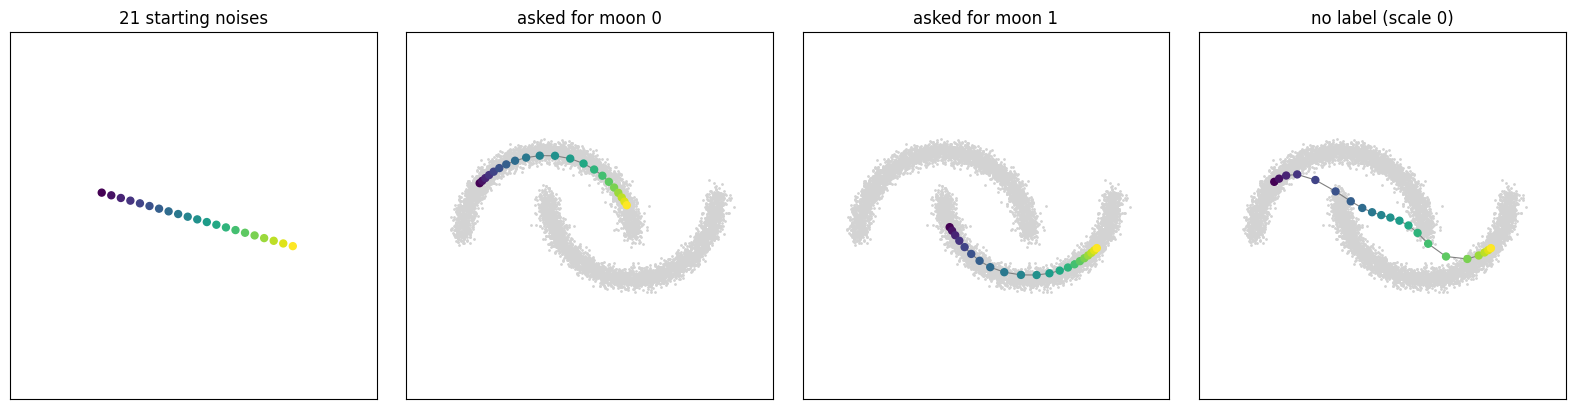

In [12]:
K = 21
u = np.linspace(0, 1, K)[:, None].astype("float32")
z_a, z_b = np.array([[-1.2, 0.3]], dtype="float32"), np.array([[1.3, -0.4]], dtype="float32")
line = (1 - u) * z_a + u * z_b                                          # 21 noises on a straight line
walks = {}
for name, lab, w in (("asked for moon 0", 0, 1), ("asked for moon 1", 1, 1), ("no label (scale 0)", 0, 0)):
    p = ddim_sample(Guided(cond, np.full(K, lab), w), SCHED, K, 100, x_start=line)
    walks[name] = p
    hop = np.linalg.norm(np.diff(p, axis=0), axis=1)
    off = int((nearest_dist(p, X) > 0.1).sum())
    print(f"{name:20s} from {p[0].round(2)} to {p[-1].round(2)} | biggest hop {hop.max():.2f} | points on no moon: {off} of {K}")

# and many pairs, with no label: what happens when the two ends land on different moons?
rng = np.random.default_rng(3)
PAIRS = 300
za, zb = rng.standard_normal((PAIRS, 1, 2)), rng.standard_normal((PAIRS, 1, 2))
many = ((1 - u[None]) * za + u[None] * zb).reshape(-1, 2).astype("float32")
ends = ddim_sample(Guided(cond, np.zeros(len(many), dtype="int32"), 0), SCHED, len(many), 100, x_start=many)
on_moon0 = (nearest_dist(ends, MOON[0]) < nearest_dist(ends, MOON[1])).reshape(PAIRS, K)
off_any = (nearest_dist(ends, X) > 0.1).reshape(PAIRS, K)
crosses = on_moon0[:, 0] != on_moon0[:, -1]
print(f"\n{PAIRS} random pairs, no label: {100 * crosses.mean():.0f}% end on different moons")
INTERP = (100 * off_any[crosses][:, 1:-1].mean(), 100 * off_any[~crosses][:, 1:-1].mean())
print(f"in-between points on no moon: {INTERP[0]:.0f}% when the ends are on different moons, {INTERP[1]:.0f}% when on the same")

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].scatter(line[:, 0], line[:, 1], c=u[:, 0], cmap="viridis", s=25); lims(ax[0], 2.4); ax[0].set_title("21 starting noises")
for a_, (name, p) in zip(ax[1:], walks.items()):
    a_.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a_.plot(p[:, 0], p[:, 1], "-", color="grey", lw=0.8)
    a_.scatter(p[:, 0], p[:, 1], c=u[:, 0], cmap="viridis", s=25, zorder=3); lims(a_, 2.4); a_.set_title(name)
plt.tight_layout(); plt.show()

### Why we see this

With the label fixed, the 21 results walk along the requested moon in small, even hops, and every one
of them is on the moon. Sliding between two noises slides smoothly between two samples. In an image
model this is the smooth "morph" between two pictures of the same prompt.

With no label, this pair of noises ends on different moons, and the walk has to get from one to the
other. A continuous map cannot jump, so a few in-between noises are sent to places **between** the moons
where there is no data. Over 300 random pairs, in-between points are off the data more than twice as
often when the two ends are on different moons as when they are on the same one. Interpolating between
seeds is smooth **within** one kind of thing and passes through nonsense on the way from one kind to
another.

In two dimensions a straight line between two noises is good enough. In 256 or 16,384 dimensions it is
not, and Step 20 shows why.

---
## Step 13 - Guidance and few steps together

Real systems use both at once: guidance, and a deterministic sampler with few steps. Do the two get on?

> **Predict:** at scale 3 the ancestral sampler with 1,000 steps left almost no points off the moons
> (Step 6). Will the deterministic sampler with 100 steps do as well at scale 3? With 20?

In [13]:
print(f"{'':30s} obeys / off / spread / miss")
judge_points(by_scale[3], WANT, "scale 3, ancestral, 1,000")
COMBO = {}
for k in (1000, 100, 20):
    COMBO[k] = judge_points(ddim_sample(Guided(cond, WANT, 3), SCHED, len(WANT), k, seed=SEED), WANT, f"scale 3, deterministic, {k}")
COMBO["r20"] = judge_points(ddim_sample(Guided(cond, WANT, 3), SCHED, len(WANT), 20, seed=SEED, eta=1.0), WANT, "scale 3, random (eta 1), 20")
COMBO["s2"] = judge_points(ddim_sample(Guided(cond, WANT, 2), SCHED, len(WANT), 20, seed=SEED), WANT, "scale 2, deterministic, 20")

                               obeys / off / spread / miss


scale 3, ancestral, 1,000      obeys 100.0% | off   0.1% | spread 0.65 | miss 0.027


scale 3, deterministic, 1000   obeys 100.0% | off   2.6% | spread 0.55 | miss 0.052


scale 3, deterministic, 100    obeys 100.0% | off   2.6% | spread 0.54 | miss 0.057


scale 3, deterministic, 20     obeys 100.0% | off   2.2% | spread 0.48 | miss 0.084


scale 3, random (eta 1), 20    obeys 100.0% | off   1.4% | spread 0.55 | miss 0.046


scale 2, deterministic, 20     obeys 100.0% | off   0.2% | spread 0.60 | miss 0.047


### Why we see this

Guidance makes the sampler's job harder. The deterministic sampler at scale 3 leaves more points off
the moons and covers them worse than the ancestral sampler did at the same scale, and taking 1,000
steps does not rescue it, so the cause is not the step size. A common reading: guidance pushes every
point the same way at every step, and a deterministic sampler has nothing that pulls a point back once
it has been pushed too far. Fresh noise shakes points loose and lets later steps correct them, and the
random sampler does hold up better here. A lower scale is the other cure.

The practical rule: **the guidance scale, the sampler and the step count are tuned together.** A scale
that looks right with one sampler can be too much with another.

---
## Step 14 - Editing: start part-way up the ladder

Sampling does not have to start from pure noise. Take an existing sample, noise it to some step with
`q_sample`, and run the sampler down from **there**, with a new request. The step you start from is how
much of the original you agree to forget.

Here: 1,000 real points of **moon 0** are noised to step 25, 50, 100, 200, 400 or 1,000, and the
sampler is asked to bring them back as **moon 1** (and, for comparison, as moon 0 again).

> **Predict:** the gap between the two moons is about 0.3 wide. The noise weight is 0.09 at step 25,
> 0.32 at step 100 and 0.90 at step 400. From which starting step could a noisy moon-0 point pass for a
> noisy moon-1 point, so that the request can be met? And what becomes of the points when the request
> cannot quite be met?

In [14]:
src = MOON[0][:1000]                                                    # 1,000 real points of moon 0
rng = np.random.default_rng(SEED)
eps_edit = rng.standard_normal(src.shape).astype("float32")
EDIT = {}
print(f"{'':10s} {'':12s} | {'asked for moon 1':^30s} | {'asked for moon 0 again':^24s}")
print(f"{'start step':>10} {'noise weight':>12} | {'now on moon 1':>14} {'on no moon':>15} | {'distance from the original':>24}")
for s0 in (25, 50, 100, 200, 400, 1000):
    noisy = q_sample(src, np.full(len(src), s0), eps_edit, SCHED)
    k = max(s0 // 5, 5)                                                 # strides of 5 steps
    to1 = ddim_sample(Guided(cond, np.ones(len(src)), 1), SCHED, len(src), k, x_start=noisy, start=s0)
    to0 = ddim_sample(Guided(cond, np.zeros(len(src)), 1), SCHED, len(src), k, x_start=noisy, start=s0)
    d1, d0 = nearest_dist(to1, MOON[1]), nearest_dist(to1, MOON[0])
    EDIT[s0] = (100 * float((d1 < d0).mean()), 100 * float((np.minimum(d1, d0) > 0.1).mean()), float(np.linalg.norm(to0 - src, axis=1).mean()))
    print(f"{s0:10d} {SCHED['noise'][s0]:12.2f} | {EDIT[s0][0]:13.1f}% {EDIT[s0][1]:14.1f}% | {EDIT[s0][2]:24.2f}")
print(f"for scale: two unrelated points of moon 0 are {np.linalg.norm(src - src[::-1], axis=1).mean():.2f} apart on average")

                        |        asked for moon 1        |  asked for moon 0 again 
start step noise weight |  now on moon 1      on no moon | distance from the original
        25         0.09 |           5.9%           44.5% |                     0.10


        50         0.17 |          63.1%           62.9% |                     0.16


       100         0.32 |          96.5%           17.4% |                     0.28


       200         0.58 |          99.6%            2.0% |                     0.51


       400         0.90 |          99.8%            0.6% |                     0.82


      1000         1.00 |         100.0%            0.2% |                     1.03
for scale: two unrelated points of moon 0 are 1.05 apart on average


### Why we see this

Read the right-hand column first. Asked for the same moon again, a point comes back close to where it
was when the start is low (0.10 from step 25) and anywhere on its moon when the start is high (from
step 1,000 it is as far from the original as an unrelated point). The starting step is a dial for **how
much of the original survives**.

Now the new request. From step 200 upwards it is met: practically every point arrives on moon 1,
cleanly. **Below that is the bad zone.** From step 25 few points reach moon 1, yet nearly half have
been dragged off moon 0. From step 50 well over half are on **no moon at all**: the sampler was pulled
towards the new request and ran out of steps before it could finish the journey.

This is **image-to-image** generation, and the starting step, as a fraction of T, is the dial usually
called *strength* or *denoising strength*. Low strength keeps the original and can only retouch it.
High strength obeys the new request and keeps little. A request that contradicts the picture, at a
strength too low to carry it out, gives a muddle that is neither.

---
# Part B - The same thing on small digits

## Step 15 - Digits, their labels, and a judge

Chapter 50's 16 × 16 digits, scaled to -1 ... 1, this time with their labels 0 to 9. Nobody can check
200 generated digits by eye every time a dial moves, so we also train a **judge**: a small ordinary
classifier (Chapter 16) on the real digits. Its only job is to say which digit a generated picture
looks like.

> **Predict:** the judge is a tiny CNN trained for a few seconds. How accurate will it be on real digits
> it has not seen? What accuracy would you **need** before trusting it to grade a generator?

In [15]:
def shrink(a):
    """28 x 28 bytes -> 16 x 16 floats in -1 ... 1 (pad to 32, then average 2 x 2), as in Chapter 50."""
    a = a.astype("float32") / 127.5 - 1.0
    a = np.pad(a, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)
    return a.reshape(len(a), 16, 2, 16, 2).mean(axis=(2, 4))[..., None]

(x_train, y_train), _ = keras.datasets.mnist.load_data()
N_IMG = 30_000
imgs, labs = shrink(x_train[:N_IMG]), y_train[:N_IMG].astype("int32")
HELD, HELD_Y = shrink(x_train[50_000:52_000]), y_train[50_000:52_000].astype("int32")   # never trained on
print("images:", imgs.shape, "| range", imgs.min(), "to", imgs.max(), "| labels:", np.bincount(labs))

keras.utils.set_random_seed(SEED)
judge = keras.Sequential([
    layers.Input(shape=(16, 16, 1)),
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, activation="relu"), layers.Flatten(),
    layers.Dense(10),
], name="judge")
judge.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
judge.fit(imgs, labs, epochs=3, batch_size=128, verbose=0)
JUDGE_ACC = judge.evaluate(HELD, HELD_Y, verbose=0)[1]
assert judge.count_params() == (9 * 1 + 1) * 16 + (9 * 16 + 1) * 32 + (5 * 5 * 32 + 1) * 10 == 12_810
print(f"judge: {judge.count_params():,} parameters | accuracy on 2,000 held-out real digits: {100 * JUDGE_ACC:.1f}%")

def digit_spread(d, y):
    """Variety: how much the pictures of one digit differ from each other (pixel standard deviation), averaged."""
    return float(np.mean([d[y == c].std(axis=0).mean() for c in range(10)]))

def judge_digits(d, want, name):
    agree = 100 * float((judge.predict(d, verbose=0).argmax(1) == want).mean())
    out = (agree, digit_spread(d, want), 100 * float((d > 0).mean()), 100 * float((np.abs(d) > 0.9).mean()))
    print(f"{name:26s} judge agrees {out[0]:5.1f}% | spread {out[1]:.3f} | ink {out[2]:4.1f}% | crisp pixels {out[3]:4.1f}%")
    return out

REAL_DIGITS = judge_digits(HELD, HELD_Y, "2,000 real digits")

images: (30000, 16, 16, 1) | range -1.0 to 1.0 | labels: [2961 3423 2948 3073 2926 2709 2975 3107 2875 3003]


judge: 12,810 parameters | accuracy on 2,000 held-out real digits: 97.0%
2,000 real digits          judge agrees  97.0% | spread 0.202 | ink  9.7% | crisp pixels 84.9%


### Why we see this

The judge is right on about 97% of real digits, so its verdicts on generated digits carry an error of a
few points. That is good enough to tell 11% from 80% from 100%, which is all we ask of it. It is **not**
a judge of beauty: it will happily name a blurred or broken digit. Keep that limit in mind in Step 19.

The line for real digits is the yardstick for three more numbers. **Spread** is how much pictures of the
same digit differ from each other, pixel by pixel. **Ink** is the share of pixels brighter than
mid-grey. **Crisp pixels** is the share that are nearly pure paper or pure ink; a blurred picture has
fewer.

---
## Step 16 - The conditional U-Net, counted

Chapter 50's U-Net passed the time through one Dense layer to get a 64-number vector, and fed that
vector into every block. The digit label goes in by the same door: a table with **11** rows (ten digits
and "no label") of 64 numbers, added to the time vector.

> **Predict:** Chapter 50's U-Net denoiser has 129,265 parameters. What is the new total?

In [16]:
def conv_block(x, filters, temb, name):
    """Two 3x3 convolutions, with the time vector added (one number per channel) between them."""
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv1")(x)
    tvec = layers.Dense(filters, name=name + "_time")(temb)                 # (batch, filters)
    x = layers.Add(name=name + "_add_time")([x, layers.Reshape((1, 1, filters), name=name + "_t11")(tvec)])
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv2")(x)
    return x

def build_unet_denoiser(input_shape=(16, 16, 1), base=16, depth=2, emb_dim=32, n_labels=None, name="unet_denoiser"):
    """Chapter 50's U-Net denoiser. With n_labels=None it is that network exactly: inputs [x_t, t].
    With n_labels=10 it takes a third input, a label 0 ... 10 (10 = "no label"), added to the time vector."""
    x_in = layers.Input(shape=input_shape, name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    temb = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    temb = layers.Dense(4 * base, activation="swish", name="time_dense")(temb)
    inputs = [x_in, t_in]
    if n_labels is not None:                                                # NEW: the label joins the time vector
        c_in = layers.Input(shape=(), dtype="int32", name="label")
        temb = layers.Add(name="time_plus_label")([temb, layers.Embedding(n_labels + 1, 4 * base, name="label_embedding")(c_in)])
        inputs.append(c_in)
    x, bridges = x_in, []
    for i in range(depth):                                       # the contracting path
        x = conv_block(x, base * 2 ** i, temb, f"down{i + 1}")
        bridges.append(x)
        x = layers.MaxPooling2D(2, name=f"pool{i + 1}")(x)
    x = conv_block(x, base * 2 ** depth, temb, "bottom")         # the bottom of the U
    for i in reversed(range(depth)):                             # the expanding path
        f = base * 2 ** i
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i + 1}")(x)
        x = layers.Concatenate(name=f"bridge{i + 1}")([bridges[i], x])
        x = conv_block(x, f, temb, f"dec{i + 1}")
    out = layers.Conv2D(input_shape[-1], 1, name="noise")(x)     # no activation
    return keras.Model(inputs, out, name=name)

UNET_50 = build_unet_denoiser().count_params()
digit_table = 11 * 64
print(f"Chapter 50's U-Net denoiser  : {UNET_50:,}")
print(f"label table, 11 rows x 64    : {digit_table:,}")
keras.utils.set_random_seed(SEED)
unet = build_unet_denoiser(n_labels=10, name="cond_unet_denoiser")
assert UNET_50 == 129_265 and unet.count_params() == UNET_50 + digit_table == 129_969
print(f"conditional U-Net            : {unet.count_params():,}  ({100 * digit_table / unet.count_params():.2f}% of it is the label table)")
print("inputs:", [tuple(i.shape) for i in unet.inputs], "-> output:", unet.output_shape)

Chapter 50's U-Net denoiser  : 129,265
label table, 11 rows x 64    : 704
conditional U-Net            : 129,969  (0.54% of it is the label table)
inputs: [(None, 16, 16, 1), (None,), (None,)] -> output: (None, 16, 16, 1)


### Why we see this

129,265 + 704 = **129,969**. Half a per cent of the weights carry the request. Because the label vector
is added to the time vector, it reaches **every** block of the U-Net through the Dense layers that
already carried the time, and shifts every channel up or down. The same filters can then draw a loop
when told "0" and a stroke when told "1".

---
## Step 17 - Train on labelled digits

The same `train_cond_denoiser` as in Part A, with `null=10` and 15% of the labels hidden. Twelve passes
over 30,000 digits: this is the long cell of the lab.

> **Predict:** Chapter 50's unconditional U-Net, trained a little longer than this, reached a loss near
> 0.04. Will the label make a visible difference to the **loss**? Will it make one to the **digits**?

In [17]:
t0 = time.time()
hist_b = train_cond_denoiser(unet, imgs, labs, SCHED, rounds=12, reps=1, batch=128, seed=SEED, null=10)
print(f"trained in {time.time() - t0:.0f} s: {12 * int(np.ceil(N_IMG / 128)):,} steps of batch 128")

round   1 / 12   loss 0.1645


round   2 / 12   loss 0.0684


round   3 / 12   loss 0.0559


round   4 / 12   loss 0.0510


round   5 / 12   loss 0.0472


round   6 / 12   loss 0.0453


... (2 outputs left out)

round   9 / 12   loss 0.0410


round  10 / 12   loss 0.0404


round  11 / 12   loss 0.0412


round  12 / 12   loss 0.0398
trained in 62 s: 2,820 steps of batch 128


### Why we see this

The loss ends about where Chapter 50's did. A label helps at the middle noise levels only (Step 5), and
those are a small part of the average. Whether it helps the digits, the loss will not say. Sample.

---
## Step 18 - The guidance dial on digits

Ask for 20 of each digit, 200 pictures, at scales 0, 1, 3 and 7. The sampler is the deterministic one
with **50 steps** and `clip=1.0`, from the same starting noise at every scale, so that each column of
the picture shows one seed under four settings of the dial.

> **Predict:** at scale 0 the judge should agree with the request about 10% of the time (chance). At
> scale 1, with a small model trained for about a minute: 99%, or noticeably less? And what will
> happen to the spread and to the amount of ink as the scale rises?

scale 0  (0.7 s)           judge agrees   8.5% | spread 0.221 | ink  8.9% | crisp pixels 81.7%


scale 1  (0.5 s)           judge agrees  80.0% | spread 0.185 | ink  9.0% | crisp pixels 81.6%


scale 3  (1.1 s)           judge agrees  99.5% | spread 0.154 | ink 11.6% | crisp pixels 81.5%


scale 7  (0.9 s)           judge agrees 100.0% | spread 0.148 | ink 13.7% | crisp pixels 80.4%
real digits: spread 0.202 | ink 9.7% | crisp pixels 84.9%


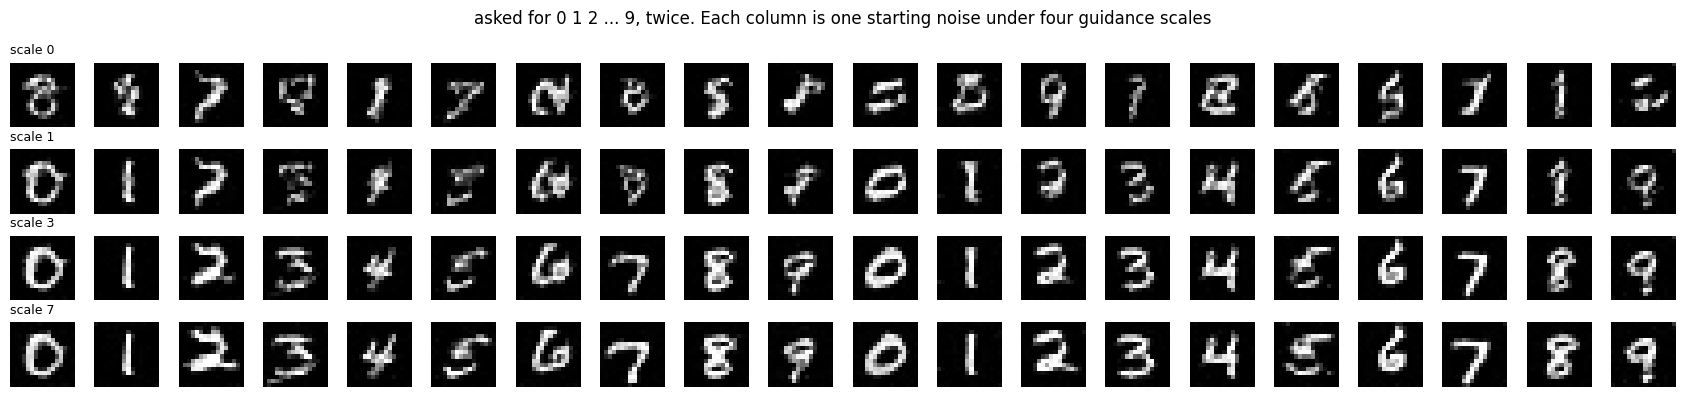

In [18]:
WANT_D = np.tile(np.arange(10), 20).astype("int32")                     # 0 1 2 ... 9, twenty times
digits_by_scale, score_digits = {}, {}
for w in SCALES:
    t0 = time.time()
    digits_by_scale[w] = ddim_sample(Guided(unet, WANT_D, w, null=10), SCHED, len(WANT_D), 50, shape=(16, 16, 1), seed=SEED, clip=1.0)
    score_digits[w] = judge_digits(digits_by_scale[w], WANT_D, f"scale {w}  ({time.time() - t0:.1f} s)")
print(f"real digits: spread {REAL_DIGITS[1]:.3f} | ink {REAL_DIGITS[2]:.1f}% | crisp pixels {REAL_DIGITS[3]:.1f}%")

fig, ax = plt.subplots(4, 20, figsize=(17, 4))
for r, w in enumerate(SCALES):
    for j in range(20):
        ax[r, j].imshow(digits_by_scale[w][j, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[r, j].axis("off")
    ax[r, 0].set_title(f"scale {w}", fontsize=9, loc="left")
plt.suptitle("asked for 0 1 2 ... 9, twice. Each column is one starting noise under four guidance scales"); plt.tight_layout(); plt.show()

### Why we see this

This is the result that Step 6 could not show, because moons were too easy. At **scale 0** the judge
agrees with the request at the rate of chance. At **scale 1**, the conditional model with no guidance,
it agrees for roughly four pictures in five: the small network has learnt the label, loosely. At
**scale 3** practically every picture is the digit that was asked for. Guidance turned a model that
mostly listens into one that listens.

The price is in the next column. The spread among pictures of the same digit falls with every increase
of the scale and is well below the real digits' at scale 3: the sevens look more like each other, and
like the most typical seven. In the grid, the unguided rows have more odd, personal shapes, and more
failures; the guided rows are tidier and more alike.

At **scale 7** the ink share has climbed well past the real digits': strokes have thickened and
hardened. This is the digit version of the over-saturated, high-contrast look of an image made with
the guidance scale set too high. The judge does not mind, which is a reminder that **a classifier's
agreement measures obedience, not quality.**

Chapter 50 promised that the label "helps more than you might expect". Compare any guided row with the
digits of the Chapter 50 lab, of which about half were readable.

---
## Step 19 - How few steps on digits?

The same question as Step 10, on pictures, at scale 3, from the same starting noise.

> **Predict:** the 2-D samples broke between 10 and 5 steps. Will the digits break at about the same
> place? And will the judge notice?

200 steps ( 3.6 s)         judge agrees  99.5% | spread 0.156 | ink 11.5% | crisp pixels 81.8%


 50 steps ( 0.9 s)         judge agrees  99.5% | spread 0.154 | ink 11.6% | crisp pixels 81.5%


 20 steps ( 0.4 s)         judge agrees  99.5% | spread 0.147 | ink 11.4% | crisp pixels 81.0%


 10 steps ( 0.2 s)         judge agrees 100.0% | spread 0.140 | ink 11.6% | crisp pixels 79.4%
  5 steps ( 0.1 s)         judge agrees 100.0% | spread 0.135 | ink 11.3% | crisp pixels 74.6%


  3 steps ( 0.1 s)         judge agrees  99.5% | spread 0.138 | ink 11.1% | crisp pixels 67.1%
RMS pixel difference from the 200-step picture of the same noise: {50: 0.015, 20: 0.034, 10: 0.068, 5: 0.13, 3: 0.203}


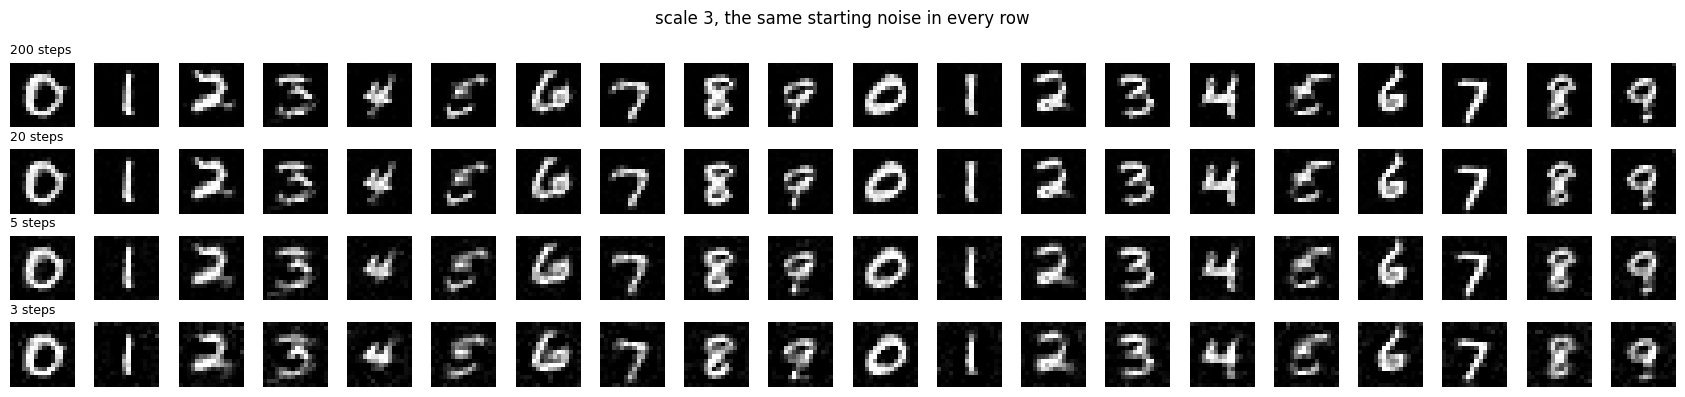

In [19]:
digits_by_steps, score_dsteps = {}, {}
for k in (200, 50, 20, 10, 5, 3):
    t0 = time.time()
    digits_by_steps[k] = ddim_sample(Guided(unet, WANT_D, 3, null=10), SCHED, len(WANT_D), k, shape=(16, 16, 1), seed=SEED, clip=1.0)
    score_dsteps[k] = judge_digits(digits_by_steps[k], WANT_D, f"{k:3d} steps ({time.time() - t0:4.1f} s)")
same = lambda k: float(np.sqrt(((digits_by_steps[k] - digits_by_steps[200]) ** 2).mean()))
print("RMS pixel difference from the 200-step picture of the same noise:", {k: round(same(k), 3) for k in (50, 20, 10, 5, 3)})

fig, ax = plt.subplots(4, 20, figsize=(17, 4))
for r, k in enumerate((200, 20, 5, 3)):
    for j in range(20):
        ax[r, j].imshow(digits_by_steps[k][j, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[r, j].axis("off")
    ax[r, 0].set_title(f"{k} steps", fontsize=9, loc="left")
plt.suptitle("scale 3, the same starting noise in every row"); plt.tight_layout(); plt.show()

### Why we see this

The judge agrees with practically everything, down to 3 steps. The pictures do not agree with the
judge. Look at the "crisp pixels" column and at the grid. With 20 steps the digits are close to the
200-step ones. With 5 and 3 they are **unfinished**: the paper is speckled with grey and the strokes
have soft edges, because too few strides leave some of the noise in and some of the detail out. A
speckled 7 is still a 7 to a classifier.

Each column keeps its identity as the steps fall: the same noise gives the same digit in the same
handwriting, less and less finished. That is Step 11 again, in pictures, and the last line of the output
puts a number on it.

So on these digits 20 steps are enough and 5 are not, the same answer as on the moons. Do not carry the
numbers 20 and 5 away with you. Carry the **shape**: a plateau, then a cliff, and a metric that may not
see the cliff.

---
## Step 20 - One noise, ten requests; and a walk between two noises

Two last experiments with the fixed map from noise to picture.

**One noise, ten labels.** Start ten samplers from the **same** noise and ask each for a different digit.

**Between two noises.** Step 12 walked along a straight line between two noises. In 256 dimensions that
is a mistake, and the cell shows it with one number: the size of the midpoint. The repair is to walk
along the **arc** between the two noises (spherical interpolation, "slerp"), which keeps the size right.

> **Predict:** two independent noise images each have standard deviation 1. What is the standard
> deviation of their average? The sampler will be told that the average is "pure noise at step 1,000".
> Is it?

judge reads noise A's ten pictures as: [0 1 2 3 4 5 6 7 8 9]
judge reads noise B's ten pictures as: [0 1 2 3 4 5 6 7 8 9]


noise A, run a second time: largest pixel difference 0.000000
RMS pixel difference between the two noises' pictures of the same digit: 0.353

standard deviation of the noise: ends 1.07 and 0.99 | straight-line midpoint 0.75 | arc midpoint 1.03


crisp pixels in the middle picture: straight line 79% | arc 79%
judge reads the arc walk as: [3 3 3 3 3 3 3 3 3]


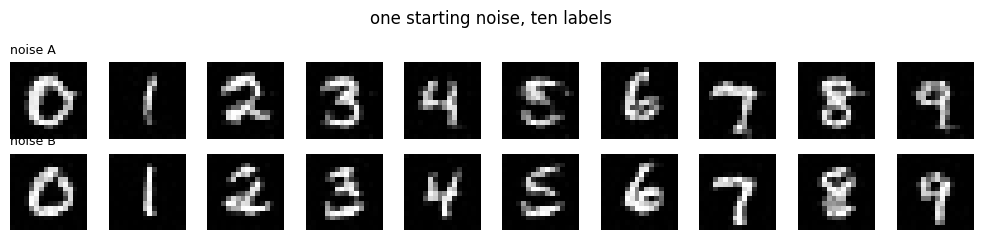

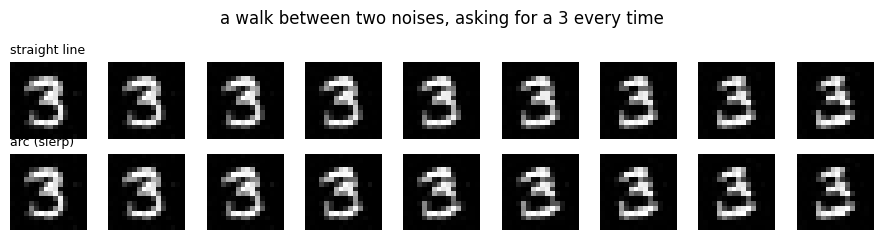


whole notebook: 234 s


In [20]:
def slerp(za, zb, u):
    """Walk along the arc from noise za to noise zb. u = 0 gives za, u = 1 gives zb."""
    a, b = za.ravel(), zb.ravel()
    angle = np.arccos(np.clip(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))
    return (np.sin((1 - u) * angle) * za + np.sin(u * angle) * zb) / np.sin(angle)

rng = np.random.default_rng(SEED)
z1 = rng.standard_normal((1, 16, 16, 1)).astype("float32")
z2 = rng.standard_normal((1, 16, 16, 1)).astype("float32")

# one noise, ten labels (two different noises, to compare)
ten = {}
for name, zz in (("noise A", z1), ("noise B", z2)):
    ten[name] = ddim_sample(Guided(unet, np.arange(10), 3, null=10), SCHED, 10, 50, shape=(16, 16, 1), x_start=np.repeat(zz, 10, axis=0), clip=1.0)
print("judge reads noise A's ten pictures as:", judge.predict(ten["noise A"], verbose=0).argmax(1))
print("judge reads noise B's ten pictures as:", judge.predict(ten["noise B"], verbose=0).argmax(1))
again = ddim_sample(Guided(unet, np.arange(10), 3, null=10), SCHED, 10, 50, shape=(16, 16, 1), x_start=np.repeat(z1, 10, axis=0), clip=1.0)
print(f"noise A, run a second time: largest pixel difference {np.abs(again - ten['noise A']).max():.6f}")
print(f"RMS pixel difference between the two noises' pictures of the same digit: {np.sqrt(((ten['noise A'] - ten['noise B']) ** 2).mean()):.3f}")

# the midpoint of a straight line, and of the arc
us = np.linspace(0, 1, 9)
straight = np.concatenate([(1 - u_) * z1 + u_ * z2 for u_ in us])
arc = np.concatenate([slerp(z1, z2, u_) for u_ in us])
print(f"\nstandard deviation of the noise: ends {z1.std():.2f} and {z2.std():.2f} | straight-line midpoint {straight[4].std():.2f} | arc midpoint {arc[4].std():.2f}")
three = np.full(9, 3)
walk_line = ddim_sample(Guided(unet, three, 3, null=10), SCHED, 9, 50, shape=(16, 16, 1), x_start=straight, clip=1.0)
walk_arc = ddim_sample(Guided(unet, three, 3, null=10), SCHED, 9, 50, shape=(16, 16, 1), x_start=arc, clip=1.0)
MID = (100 * float((np.abs(walk_line[4]) > 0.9).mean()), 100 * float((np.abs(walk_arc[4]) > 0.9).mean()))
print(f"crisp pixels in the middle picture: straight line {MID[0]:.0f}% | arc {MID[1]:.0f}%")
print("judge reads the arc walk as:", judge.predict(walk_arc, verbose=0).argmax(1))

fig, ax = plt.subplots(2, 10, figsize=(10, 2.4))
for r, name in enumerate(("noise A", "noise B")):
    for j in range(10):
        ax[r, j].imshow(ten[name][j, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[r, j].axis("off")
    ax[r, 0].set_title(name, fontsize=9, loc="left")
plt.suptitle("one starting noise, ten labels"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2, 9, figsize=(9, 2.4))
for r, (name, wk) in enumerate((("straight line", walk_line), ("arc (slerp)", walk_arc))):
    for j in range(9):
        ax[r, j].imshow(wk[j, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[r, j].axis("off")
    ax[r, 0].set_title(name, fontsize=9, loc="left")
plt.suptitle("a walk between two noises, asking for a 3 every time"); plt.tight_layout(); plt.show()
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

### Why we see this

**One noise, ten labels.** The judge reads the ten pictures as the ten digits that were asked for, for
both noises, and a second run from noise A reproduces its pictures exactly. The label decides **what**
is drawn. The noise decides **how**: compare the two rows digit by digit, and each digit is drawn in a
different hand. In a text-to-image system this is why keeping the seed and editing the prompt gives a
related picture, and why changing the seed gives a new composition of the same prompt.

**Between two noises.** The average of two independent noises has a standard deviation of about 0.71,
not 1 (these two particular draws give 0.75). The sampler is told "this is step 1,000" about something
with roughly **half the noise variance** that step 1,000 should have. The arc keeps the standard
deviation near 1 all the way.

Now the honest part. On these small digits you can hardly see the difference: both rows are nine
plausible 3s that change gradually from the first to the last, and the "crisp pixels" numbers agree.
With a strong label, guidance and a clipped clean-image guess, this little sampler recovers from a start
that is too quiet. Do not count on that. In a large model the starting noise has thousands of numbers
and the picture has fine texture to lose, and a start with too little noise gives flat, washed-out
pictures in the middle of the walk. The habit is to walk the arc, and it costs one function.

---
## Trials: change one thing at a time

Change the one line, **predict**, then rerun from that step. Write the observation in the last column.

| # | Change | Where | Predict | Observe |
|---|---|---|---|---|
| 1 | `SCALES = (0, 1, 1.5, 2)` | Step 6 | Between 1 and 2, how fast does the spread fall? Is there a scale that costs nothing? | |
| 2 | `drop=0.5` in `train_cond_denoiser` | Step 4 | Half the labels hidden. Which gets better, the unconditional answer or the conditional one? What happens at scale 1 and scale 3? | |
| 3 | Scale `-1` in Step 6 (`SCALES = (0, 1, -1, 3)`) | Step 6 | The arrow is reversed: "anything but the label". With two moons, where do the points go? | |
| 4 | `STEP_COUNTS = (1000, 8, 7, 6, 5, 4, 3)` | Step 10 | Find the cliff edge to within one step. Is it a cliff or a slope? | |
| 5 | `ts = np.unique(np.round(T * np.linspace(0, 1, steps + 1) ** 2).astype(int))` in `ddim_sample` | Step 9 | The steps now crowd towards low noise. Does a 5-step sample get better or worse? Where were the 5 steps needed? | |
| 6 | `SCHED = make_schedule(1000, "cosine")` in Step 2, and `clip=3.0` in every sampler call of Part A | Step 2 | The cosine schedule's signal weight at step 1,000 is almost exactly 0, and the samplers divide by it. What does the clip rescue? Does the cliff move? | |
| 7 | `rounds=4` in Step 17 | Step 17 | A weaker digit model. Does scale 3 still reach near 100% agreement? What do the digits look like? | |
| 8 | `eta=1.0` in Step 18 | Step 18 | Fresh noise with 50 steps. What happens to the spread, and to "each column is one seed"? | |

---
## Exercises

1. **A negative label.** Add an argument `negative=None` to `Guided` so that the base answer uses that
   label in place of `NULL`. Ask for moon 0 with moon 1 as the negative, at scales 1.5 and 3. Step 5
   showed that the wrong-label arrow is far longer than the no-label arrow: what does that do to a safe
   scale? This is how a **negative prompt** works.
2. **Start part-way.** Take 500 real points of moon 0, noise them to step 300 with `q_sample`, and run
   `ddim_sample` from there (give it `x_start`, and change the first visited step from T to 300) while
   asking for **moon 1**. Repeat from step 600 and step 900. How far up the noise ladder must you climb
   before the label can move a point to the other moon? This is image-to-image editing, and the step you
   start from is its "strength".
3. **Regenerate half.** Sample 16 digits. Then sample again from fresh noise, but after every sampler
   jump overwrite the **top half** of each picture with the original top half noised to the current step
   (`q_sample`). Does the new bottom half fit the old top? This is inpainting.
4. **A better stride.** Replace the single jump in `ddim_sample` by a two-stage one: jump to the midpoint
   step, ask the network again there, and use that second noise guess for the whole jump. It costs two
   calls per stride. At 10 calls in total, is it better than 10 plain strides? This is the idea behind
   higher-order solvers.
5. **Guidance that fades.** Step 5 showed that the label matters only between about steps 500 and 50.
   Apply guidance only inside that range (scale 1 elsewhere) and count the network inputs saved. Does
   obedience suffer?
6. **Measure the map.** For the deterministic sampler without a label, colour 5,000 starting noises by
   the moon they end on. What does the boundary between the two regions look like, and where do the
   points that start close to it end up?

---
## Cheat sheet

| Thing | In one line |
|---|---|
| condition | extra input to the denoiser; a label is an embedding added to the time vector |
| label dropping | hide the condition for 10 to 20% of training examples, so one network answers with and without it |
| guidance (our convention) | noise = unconditional + scale × (conditional − unconditional) |
| scale 0 / 1 / above 1 | ignore the request / plain conditional, no guidance / guidance |
| other convention | some papers write (1 + w) × conditional − w × unconditional; their w = 0 is our scale 1 |
| what the scale buys | obedience to the request, when the plain model follows it loosely |
| what it costs | variety falls; too high pushes samples off the data ("burnt"); two network passes per step |
| never dropped | scale 1 works, any other scale gives nonsense, and nothing warns you |
| sampler | the numerical method that walks the path the trained network defines; no weights |
| deterministic jump | x at step s = signal(s) × clean guess + noise(s) × noise guess; any s, no fresh noise |
| step count | a plateau, then a cliff; here 100 ≈ 1,000, 20 is fine, 5 is broken |
| too few steps | samples shrink towards averages: blur, lost detail |
| seed | with a deterministic sampler the starting noise fixes the output; a new sampler is a new picture |
| interpolation | smooth within one kind of thing; in many dimensions walk the arc (slerp), not the straight line |
| tuned together | guidance scale, sampler and step count |